In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv("ai4i2020.csv")

df.head()

Matplotlib is building the font cache; this may take a moment.


,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


In [2]:
# Dimensiones del dataset
print("Número de registros:", df.shape[0])
print("Número de variables:", df.shape[1])

print("\nInformación del dataset:")
df.info()

Número de registros: 10000
Número de variables: 14

Información del dataset:
<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   UDI                      10000 non-null  int64  
 1   Product ID               10000 non-null  str    
 2   Type                     10000 non-null  str    
 3   Air temperature [K]      10000 non-null  float64
 4   Process temperature [K]  10000 non-null  float64
 5   Rotational speed [rpm]   10000 non-null  int64  
 6   Torque [Nm]              10000 non-null  float64
 7   Tool wear [min]          10000 non-null  int64  
 8   Machine failure          10000 non-null  int64  
 9   TWF                      10000 non-null  int64  
 10  HDF                      10000 non-null  int64  
 11  PWF                      10000 non-null  int64  
 12  OSF                      10000 non-null  int64  
 13  RNF        

In [3]:
# Verificar valores faltantes
print("Valores faltantes por variable:")
print(df.isnull().sum())

# Verificar registros duplicados
print("\nRegistros duplicados:", df.duplicated().sum())

Valores faltantes por variable:
UDI                        0
Product ID                 0
Type                       0
Air temperature [K]        0
Process temperature [K]    0
Rotational speed [rpm]     0
Torque [Nm]                0
Tool wear [min]            0
Machine failure            0
TWF                        0
HDF                        0
PWF                        0
OSF                        0
RNF                        0
dtype: int64

Registros duplicados: 0


### Descripción inicial del dataset

El dataset contiene **10,000 registros y 14 variables** relacionadas con las condiciones de operación y fallas de maquinaria industrial.

Las principales variables de proceso son temperatura del aire, temperatura del proceso, velocidad de rotación, torque y desgaste de herramienta. La variable **Machine failure** indica si se presentó una falla en la máquina, por lo que será utilizada como variable objetivo del modelo.

También existen variables asociadas con tipos específicos de falla (TWF, HDF, PWF, OSF y RNF), las cuales serán analizadas durante la preparación de los datos para evitar introducir información que no estaría disponible antes de que ocurra una falla.

## 2. Análisis Exploratorio de Datos (EDA)

Se realiza un análisis exploratorio para comprender la distribución de las variables, 
identificar patrones en las condiciones de operación y analizar su posible relación 
con la ocurrencia de fallas en la maquinaria.

In [4]:
# Estadísticas descriptivas de las variables numéricas
df.describe().T

,count,mean,std,min,25%,50%,75%,max
UDI,10000.0,5000.50000,2886.895680,1.0,2500.75,5000.5,7500.25,10000.0
Air temperature [K],10000.0,300.00493,2.000259,295.3,298.30,300.1,301.50,304.5
Process temperature [K],10000.0,310.00556,1.483734,305.7,308.80,310.1,311.10,313.8
Rotational speed [rpm],10000.0,1538.77610,179.284096,1168.0,1423.00,1503.0,1612.00,2886.0
Torque [Nm],10000.0,39.98691,9.968934,3.8,33.20,40.1,46.80,76.6
Tool wear [min],10000.0,107.95100,63.654147,0.0,53.00,108.0,162.00,253.0
Machine failure,10000.0,0.03390,0.180981,0.0,0.00,0.0,0.00,1.0
TWF,10000.0,0.00460,0.067671,0.0,0.00,0.0,0.00,1.0
HDF,10000.0,0.01150,0.106625,0.0,0.00,0.0,0.00,1.0
PWF,10000.0,0.00950,0.097009,0.0,0.00,0.0,0.00,1.0


### Interpretación

Las estadísticas descriptivas permiten observar los rangos de operación de las principales 
variables del proceso. Se identifican diferencias importantes en variables como velocidad 
de rotación, torque y desgaste de herramienta, por lo que resulta conveniente analizar 
gráficamente sus distribuciones y su relación con las fallas.

In [5]:
# Distribución de la variable objetivo
fallas = df["Machine failure"].value_counts()

print("Distribución de fallas:")
print(fallas)

print("\nPorcentaje:")
print(df["Machine failure"].value_counts(normalize=True) * 100)

Distribución de fallas:
Machine failure
0    9661
1     339
Name: count, dtype: int64

Porcentaje:
Machine failure
0    96.61
1     3.39
Name: proportion, dtype: float64


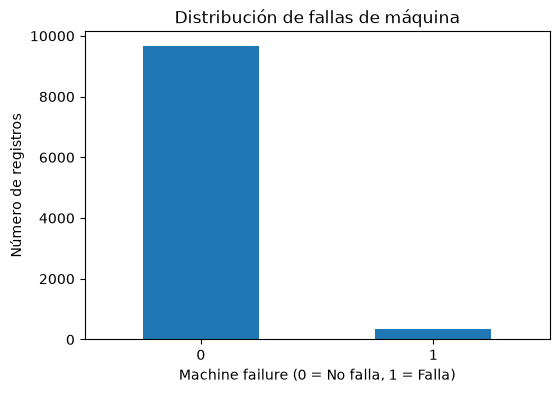

In [6]:
# Distribución de la variable objetivo
df["Machine failure"].value_counts().sort_index().plot(
    kind="bar",
    figsize=(6,4)
)

plt.title("Distribución de fallas de máquina")
plt.xlabel("Machine failure (0 = No falla, 1 = Falla)")
plt.ylabel("Número de registros")
plt.xticks(rotation=0)
plt.show()

### Interpretación

La variable objetivo presenta un desbalance importante entre las clases. La mayoría de 
los registros corresponden a condiciones sin falla, mientras que una proporción pequeña 
representa eventos de falla.

Este comportamiento es relevante para el entrenamiento del modelo, ya que utilizar 
únicamente accuracy como métrica podría generar una interpretación incorrecta del 
desempeño. Por ello, posteriormente se considerarán métricas adicionales como precision, 
recall y F1-score.

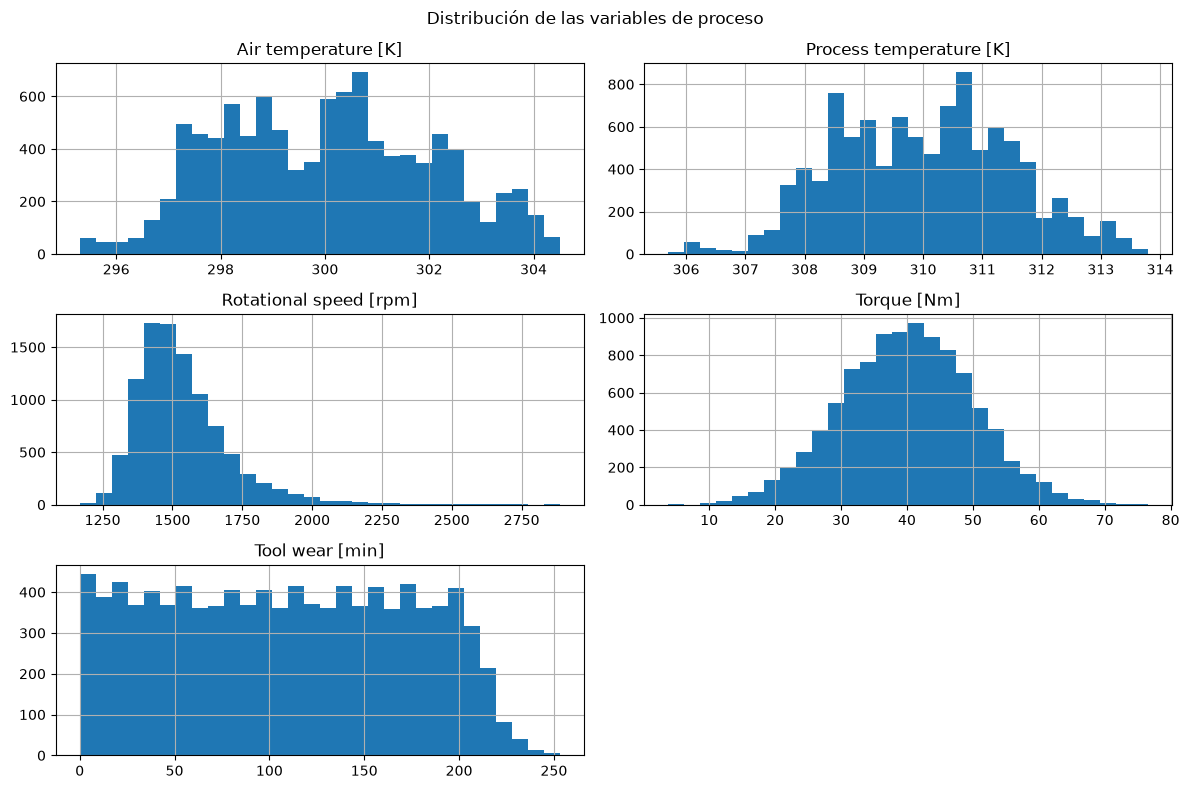

In [7]:
variables = [
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]"
]

df[variables].hist(
    bins=30,
    figsize=(12,8)
)

plt.suptitle("Distribución de las variables de proceso")
plt.tight_layout()
plt.show()

### Interpretación

Las variables presentan diferentes patrones de distribución. Las temperaturas muestran 
rangos relativamente concentrados, mientras que variables como velocidad de rotación y 
torque presentan una mayor variabilidad.

Estas diferencias permiten identificar las condiciones normales de operación y posibles 
valores extremos que deberán revisarse durante la etapa de limpieza de datos.

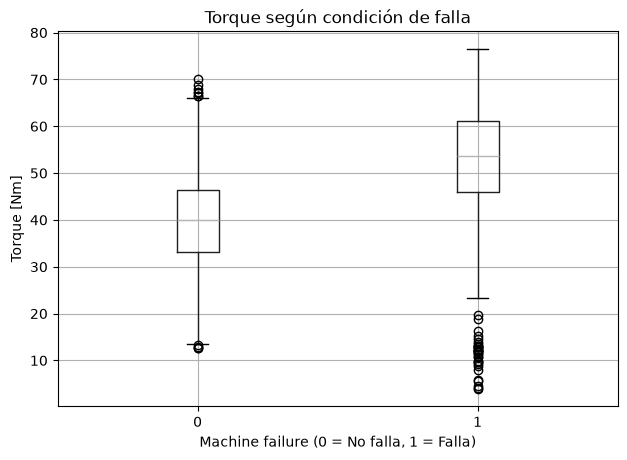

In [8]:
# Relación entre torque y falla de máquina
df.boxplot(
    column="Torque [Nm]",
    by="Machine failure",
    figsize=(7,5)
)

plt.title("Torque según condición de falla")
plt.suptitle("")
plt.xlabel("Machine failure (0 = No falla, 1 = Falla)")
plt.ylabel("Torque [Nm]")
plt.show()

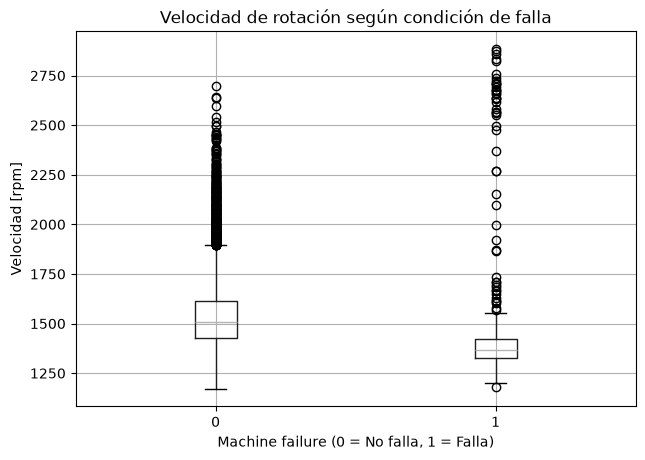

In [9]:
# Relación entre velocidad de rotación y falla
df.boxplot(
    column="Rotational speed [rpm]",
    by="Machine failure",
    figsize=(7,5)
)

plt.title("Velocidad de rotación según condición de falla")
plt.suptitle("")
plt.xlabel("Machine failure (0 = No falla, 1 = Falla)")
plt.ylabel("Velocidad [rpm]")
plt.show()

### Interpretación

Al comparar las condiciones de operación con la variable objetivo se observan diferencias 
entre los registros con y sin falla. El torque y la velocidad de rotación presentan 
variaciones que podrían estar relacionadas con una mayor probabilidad de falla.

Desde una perspectiva de mantenimiento predictivo, estas variables son relevantes porque 
representan directamente las condiciones mecánicas bajo las cuales opera el equipo.

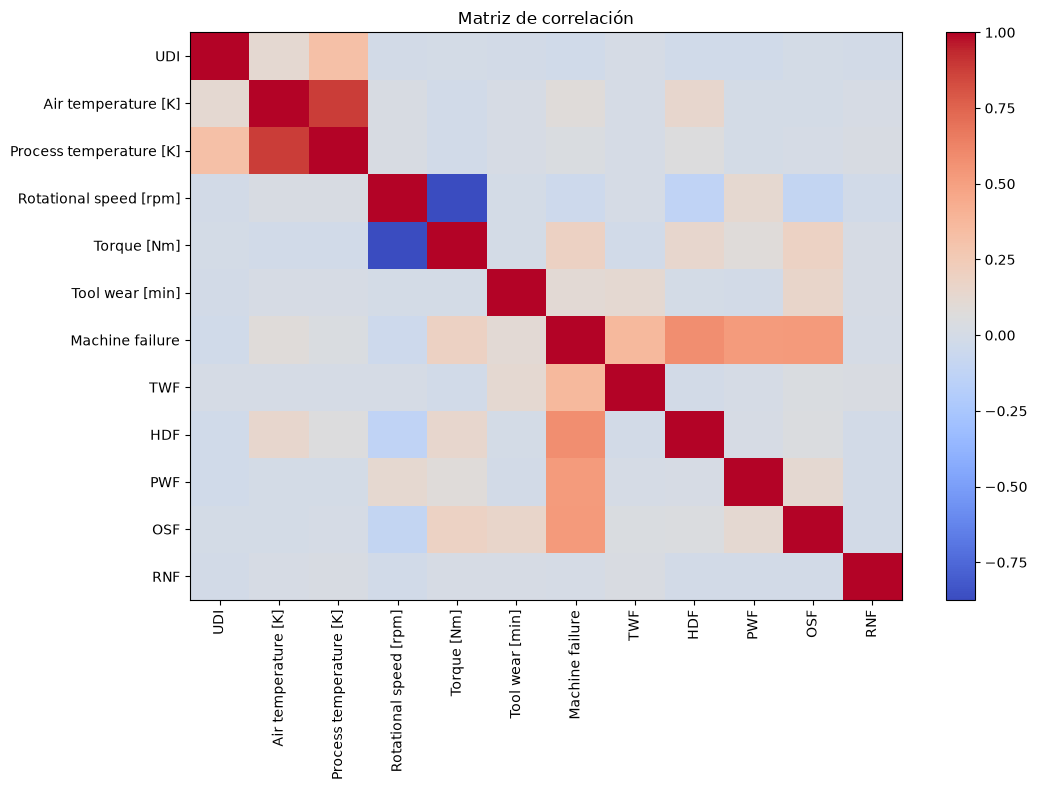

In [10]:
# Seleccionamos únicamente variables numéricas
numeric_df = df.select_dtypes(include=np.number)

# Matriz de correlación
correlation = numeric_df.corr()

plt.figure(figsize=(11,8))
plt.imshow(correlation, cmap="coolwarm", aspect="auto")
plt.colorbar()

plt.xticks(
    range(len(correlation.columns)),
    correlation.columns,
    rotation=90
)

plt.yticks(
    range(len(correlation.columns)),
    correlation.columns
)

plt.title("Matriz de correlación")
plt.tight_layout()
plt.show()

### Conclusión del EDA

El análisis exploratorio muestra que el dataset se encuentra fuertemente desbalanceado 
respecto a la ocurrencia de fallas. También se identifican relaciones entre algunas 
variables operativas y la variable objetivo.

Las variables TWF, HDF, PWF, OSF y RNF representan tipos específicos de falla. Debido a 
que esta información está directamente relacionada con la variable objetivo, utilizarla 
como entrada del modelo podría generar fuga de información (data leakage).

Por esta razón, para el modelo baseline se utilizarán principalmente las variables que 
representan condiciones disponibles durante la operación del equipo, como temperatura, 
velocidad, torque y desgaste.

## 3. Limpieza de datos

Se revisó la calidad de los datos identificando valores faltantes, registros duplicados,
tipos de datos y posibles valores atípicos.

In [11]:
# Revisar valores faltantes
print("Valores faltantes:")
print(df.isnull().sum())

# Revisar duplicados
print("\nRegistros duplicados:", df.duplicated().sum())

# Revisar tipos de datos
print("\nTipos de datos:")
print(df.dtypes)

Valores faltantes:
UDI                        0
Product ID                 0
Type                       0
Air temperature [K]        0
Process temperature [K]    0
Rotational speed [rpm]     0
Torque [Nm]                0
Tool wear [min]            0
Machine failure            0
TWF                        0
HDF                        0
PWF                        0
OSF                        0
RNF                        0
dtype: int64

Registros duplicados: 0

Tipos de datos:
UDI                          int64
Product ID                     str
Type                           str
Air temperature [K]        float64
Process temperature [K]    float64
Rotational speed [rpm]       int64
Torque [Nm]                float64
Tool wear [min]              int64
Machine failure              int64
TWF                          int64
HDF                          int64
PWF                          int64
OSF                          int64
RNF                          int64
dtype: object


### Resultados de la limpieza

No se encontraron valores faltantes ni registros duplicados. Los tipos de datos también
son adecuados para las variables analizadas, por lo que no fue necesario eliminar o
imputar registros.

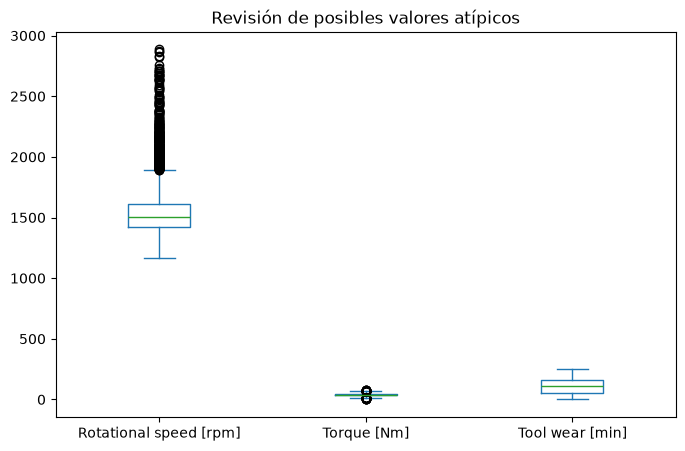

In [12]:
# Revisar posibles valores atípicos
df[
    ["Rotational speed [rpm]", "Torque [Nm]", "Tool wear [min]"]
].plot(kind="box", figsize=(8,5))

plt.title("Revisión de posibles valores atípicos")
plt.show()

Se observaron algunos valores extremos, principalmente en velocidad y torque. Sin embargo,
se decidió conservarlos porque pueden representar condiciones reales de operación asociadas
con fallas de maquinaria.

In [13]:
# Eliminar identificadores y variables que pueden generar data leakage
df_model = df.drop(
    columns=["UDI", "Product ID", "TWF", "HDF", "PWF", "OSF", "RNF"]
)

# Convertir Type a valores numéricos
df_model = pd.get_dummies(df_model, columns=["Type"], drop_first=True, dtype=int)

df_model.head()

,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,Type_L,Type_M
0,298.1,308.6,1551,42.8,0,0,0,1
1,298.2,308.7,1408,46.3,3,0,1,0
2,298.1,308.5,1498,49.4,5,0,1,0
3,298.2,308.6,1433,39.5,7,0,1,0
4,298.2,308.7,1408,40.0,9,0,1,0


Se eliminaron UDI y Product ID porque únicamente funcionan como identificadores.
También se excluyeron las variables TWF, HDF, PWF, OSF y RNF para evitar data leakage,
ya que indican directamente tipos de falla.

La variable categórica Type se convirtió a formato numérico para poder utilizarla
posteriormente en el modelo de Machine Learning.

## 4. Modelo Baseline

Se utilizará un modelo de Regresión Logística como modelo baseline, ya que el objetivo
es predecir una variable binaria: si la máquina presenta una falla (1) o no (0).

Los datos se dividirán en 80% para entrenamiento y 20% para prueba.

In [14]:
# Variables predictoras
X = df_model.drop("Machine failure", axis=1)

# Variable objetivo
y = df_model["Machine failure"]

print("Variables de entrada:", X.shape)
print("Variable objetivo:", y.shape)

Variables de entrada: (10000, 7)
Variable objetivo: (10000,)


In [15]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Datos de entrenamiento:", X_train.shape)
print("Datos de prueba:", X_test.shape)

Datos de entrenamiento: (8000, 7)
Datos de prueba: (2000, 7)


In [16]:
from sklearn.linear_model import LogisticRegression

# Crear modelo
modelo = LogisticRegression(max_iter=1000)

# Entrenar modelo
modelo.fit(X_train, y_train)

print("Modelo entrenado correctamente")

Modelo entrenado correctamente


In [17]:
# Realizar predicciones
y_pred = modelo.predict(X_test)

print("Primeras 10 predicciones:")
print(y_pred[:10])

Primeras 10 predicciones:
[1 0 0 0 0 0 0 0 0 0]


In [ ]:
### Resultado

El modelo de Regresión Logística fue entrenado utilizando el 80% de los datos y se
realizaron predicciones sobre el 20% restante.

Este modelo servirá como baseline para evaluar qué tan bien es posible predecir las
fallas utilizando las variables de operación disponibles.

## 5. Evaluación del modelo

Para evaluar el desempeño del modelo se utilizarán las métricas Accuracy, Precision,
Recall y F1-score. También se analizará la matriz de confusión para observar los
aciertos y errores en la predicción de fallas.

In [18]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

print("Accuracy:", round(accuracy, 3))
print("Precision:", round(precision, 3))
print("Recall:", round(recall, 3))
print("F1-score:", round(f1, 3))

Accuracy: 0.969
Precision: 0.667
Recall: 0.147
F1-score: 0.241


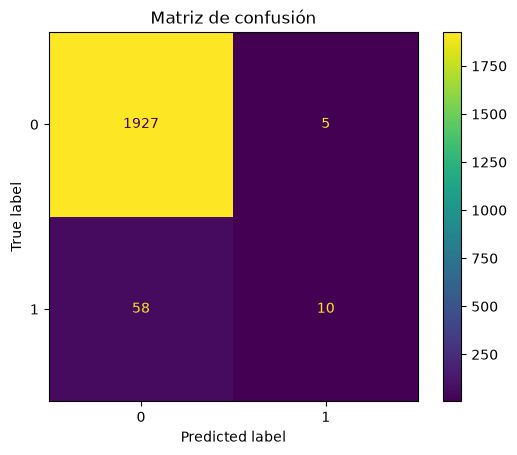

In [19]:
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred
)

plt.title("Matriz de confusión")
plt.show()

In [20]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.97      1.00      0.98      1932
           1       0.67      0.15      0.24        68

    accuracy                           0.97      2000
   macro avg       0.82      0.57      0.61      2000
weighted avg       0.96      0.97      0.96      2000



### Interpretación de resultados

El modelo presenta un Accuracy elevado; sin embargo, esta métrica debe interpretarse
con precaución debido al desbalance existente entre máquinas con y sin falla.

Para este problema resulta especialmente importante analizar el Recall de la clase de
falla, ya que indica qué proporción de las fallas reales logró identificar el modelo.

La matriz de confusión permite observar los falsos negativos, es decir, fallas reales
que el modelo no logró detectar. Desde una perspectiva de mantenimiento predictivo,
reducir este tipo de error sería particularmente importante.

In [21]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

print("Accuracy:", round(accuracy, 3))
print("Precision:", round(precision, 3))
print("Recall:", round(recall, 3))
print("F1-score:", round(f1, 3))

Accuracy: 0.969
Precision: 0.667
Recall: 0.147
F1-score: 0.241


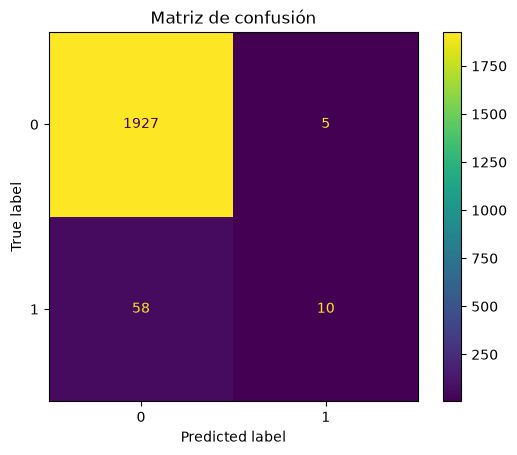

In [22]:
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(y_test, y_pred)
plt.title("Matriz de confusión")
plt.show()

In [23]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.97      1.00      0.98      1932
           1       0.67      0.15      0.24        68

    accuracy                           0.97      2000
   macro avg       0.82      0.57      0.61      2000
weighted avg       0.96      0.97      0.96      2000



### Interpretación de resultados

El modelo obtuvo un Accuracy aproximado de 97%. Sin embargo, este resultado debe
interpretarse con precaución debido al desbalance de clases presente en el dataset.

Para la clase de falla (1), el modelo obtuvo una precisión de 0.67 y un recall de
0.15. De las 68 fallas reales presentes en los datos de prueba, solamente 10 fueron
detectadas correctamente, mientras que 58 no fueron identificadas.

Esto demuestra que, aunque el modelo clasifica correctamente la mayoría de los
registros, su capacidad para detectar fallas es limitada. En un escenario de
mantenimiento predictivo sería especialmente importante mejorar el recall, ya que
una falla no detectada puede representar un mayor riesgo operativo.

## 6. Registro del experimento en MLflow

Se utiliza MLflow Tracking para registrar el modelo baseline y mantener un historial
reproducible del experimento. Se registran los parámetros principales del modelo y
las métricas obtenidas durante su evaluación.

In [24]:
import mlflow
import mlflow.sklearn

# Configurar MLflow
mlflow.set_tracking_uri("sqlite:///mlflow.db")
mlflow.set_experiment("Mantenimiento_Predictivo")

# Registrar experimento
with mlflow.start_run():

    # Parámetros
    mlflow.log_param("modelo", "LogisticRegression")
    mlflow.log_param("test_size", 0.20)
    mlflow.log_param("random_state", 42)

    # Métricas
    mlflow.log_metric("accuracy", accuracy)
    mlflow.log_metric("precision", precision)
    mlflow.log_metric("recall", recall)
    mlflow.log_metric("f1_score", f1)

    # Modelo
    mlflow.sklearn.log_model(modelo, "modelo_baseline")

print("Experimento registrado correctamente en MLflow")

2026/10/04 21:58:07 INFO mlflow.tracking.fluent: Experiment with name 'Mantenimiento_Predictivo' does not exist. Creating a new experiment.
2026/10/04 21:58:07 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.


Experimento registrado correctamente en MLflow


## 7. Reflexión final

El desarrollo de esta actividad me permitió comprender de manera práctica que un proyecto
de Machine Learning no consiste únicamente en entrenar un modelo y obtener una métrica
alta. En este caso, el modelo alcanzó un Accuracy cercano al 97%; sin embargo, al analizar
con mayor detalle los resultados observé que solamente logró identificar una pequeña
proporción de las fallas reales. Esto demuestra la importancia de seleccionar métricas
adecuadas de acuerdo con el problema que se busca resolver.

Como siguiente paso, mejoraría el modelo buscando incrementar el Recall de las fallas,
probando técnicas para tratar el desbalance de clases y comparando diferentes algoritmos.
Desde una perspectiva de MLOps, también sería importante automatizar la preparación de
los datos, registrar diferentes versiones de los modelos y monitorear su desempeño a
través del tiempo. MLflow sería útil para mantener la trazabilidad de estos experimentos
y comparar sus resultados.

Estos aprendizajes tienen una relación directa con mi área profesional, ya que trabajo
con procesos industriales donde la confiabilidad y la continuidad operativa son
fundamentales. Un modelo de mantenimiento predictivo podría utilizar variables de proceso
para identificar condiciones anormales antes de una falla. Sin embargo, para que una
herramienta de este tipo genere valor real, no basta con desarrollar el modelo: es
necesario asegurar datos confiables, seguimiento continuo y una integración adecuada
con la operación y las decisiones de mantenimiento.